# Atom Deterministic Loading -- time-budget analysis

Driver for `analyze_atom_load_deterministic.py`. Run in the **working BLAS**
Python env (not artiq7_claude -- matplotlib crashes there).

The loading test is now a **single-run MOT-formation scan**: one run sweeps
the MOT time (interleaved, so drift averages out) and tags every shot with
its MOT value. Pointing the analysis at that **one RID** plots the whole scan.

In [28]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
ANALYSIS_DIR = Path("C:/Networking Experiment/Artiq7_TEST_NEW/useful_codes/repository/analysis")
for p in (str(ANALYSIS_DIR.parent), str(ANALYSIS_DIR)):
    if p not in sys.path: sys.path.insert(0, p)
from analyze_atom_load_deterministic import (
    find_runs, load_run, summarize, print_summary, plot_single,
    plot_scan, print_scan, analyze_single, analyze_scan, analyze_scan_file,
    summarize_file_scan, distinct_mots, _rid_of, RESULTS_DIR)
%matplotlib inline
print('Setup complete'); print('Results dir:', RESULTS_DIR)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Setup complete
Results dir: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results


## 1. Latest run
Auto-detects: a single-point run shows the time budget; a scan run shows the
whole MOT curve.

File: 000003601-AtomLoadDeterministicTest.h5   RID=3601   8 MOT points, 2400 shots total (300 per point)

=== MOT-formation scan ===
     RID   MOT ms   succ %   poll ms   total ms   n_tries
    3601       20    100.0       182        202        45
    3601       40    100.0         4         44         1
    3601       60    100.0         4         64         1
    3601       80    100.0         4         84         1
    3601      100    100.0         4        104         1
    3601      120    100.0         4        124         1
    3601      140    100.0         4        144         1
    3601      160    100.0         4        164         1

  Fastest TOTAL per load : MOT 40 ms (RID 3601), 44 ms/load = 40 MOT + 4 poll.
                           ~120 ms/load faster than the longest MOT scanned (160 ms, 164 ms).
  Reliability floor      : loads >=99% down to 20 ms MOT, but that costs 202 ms/load (poll blows up) -- not worth it.
  NOTE: success is ~100% across the whole scan, so re

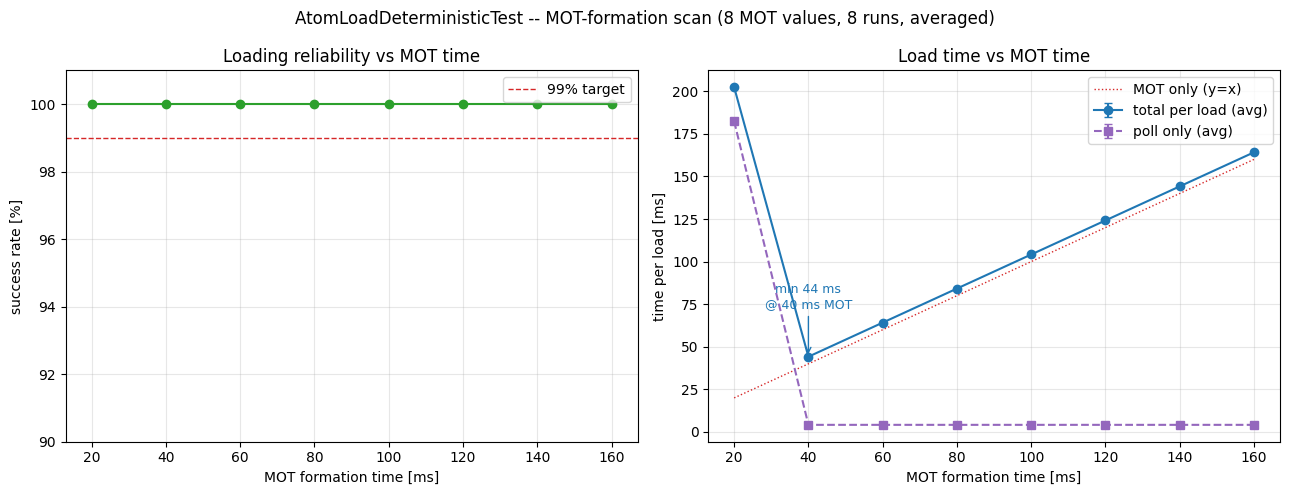

In [29]:
s = analyze_single(find_runs()[-1])

## 2. A specific RID
Set `RID` to your scan run. If it is a scan, this plots the averaged
MOT-time curve and prints the fastest-total verdict; if single-point, the
budget panels.

File: 000003601-AtomLoadDeterministicTest.h5   RID=3601   8 MOT points, 2400 shots total (300 per point)

=== MOT-formation scan ===
     RID   MOT ms   succ %   poll ms   total ms   n_tries
    3601       20    100.0       182        202        45
    3601       40    100.0         4         44         1
    3601       60    100.0         4         64         1
    3601       80    100.0         4         84         1
    3601      100    100.0         4        104         1
    3601      120    100.0         4        124         1
    3601      140    100.0         4        144         1
    3601      160    100.0         4        164         1

  Fastest TOTAL per load : MOT 40 ms (RID 3601), 44 ms/load = 40 MOT + 4 poll.
                           ~120 ms/load faster than the longest MOT scanned (160 ms, 164 ms).
  Reliability floor      : loads >=99% down to 20 ms MOT, but that costs 202 ms/load (poll blows up) -- not worth it.
  NOTE: success is ~100% across the whole scan, so re

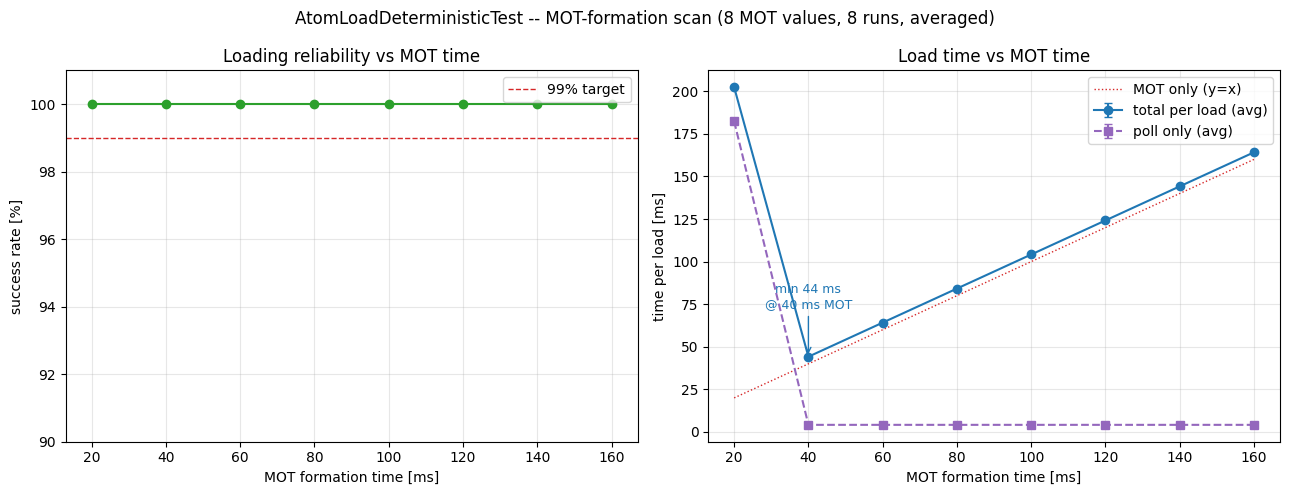

In [30]:
RID = 3601   # <-- set to your scan RID
path = [f for f in find_runs() if _rid_of(f) == RID][-1]
rows = analyze_single(path)

### Peek at the MOT values a run actually contains

In [31]:
d = load_run(path)
print('MOT points (ms) in this file:', distinct_mots(d))
print('total shots:', len(d['success']))

MOT points (ms) in this file: [np.int64(20), np.int64(40), np.int64(60), np.int64(80), np.int64(100), np.int64(120), np.int64(140), np.int64(160)]
total shots: 2400


## 3. Legacy: combine several OLD one-MOT-per-run files
For the earlier scans where each MOT value was a separate run, list the RIDs
(or use the last-N form). Not needed for the new single-run scan.


=== MOT-formation scan ===
     RID   MOT ms   succ %   poll ms   total ms   n_tries
    3584       50    100.0        85        135        21
    3593       50    100.0        85        135        21
    3585       70    100.0        73        143        18
    3594       70    100.0        81        151        20
    3586       90    100.0        73        163        18
    3595       90    100.0        93        183        23

  Fastest TOTAL per load : MOT 50 ms (RID 3584), 135 ms/load = 50 MOT + 85 poll.
                           ~28 ms/load faster than the longest MOT scanned (90 ms, 163 ms).
  NOTE: success is ~100% across the whole scan, so reliability is NOT the limiter here -- optimize for total time, and mind run-to-run loading drift.


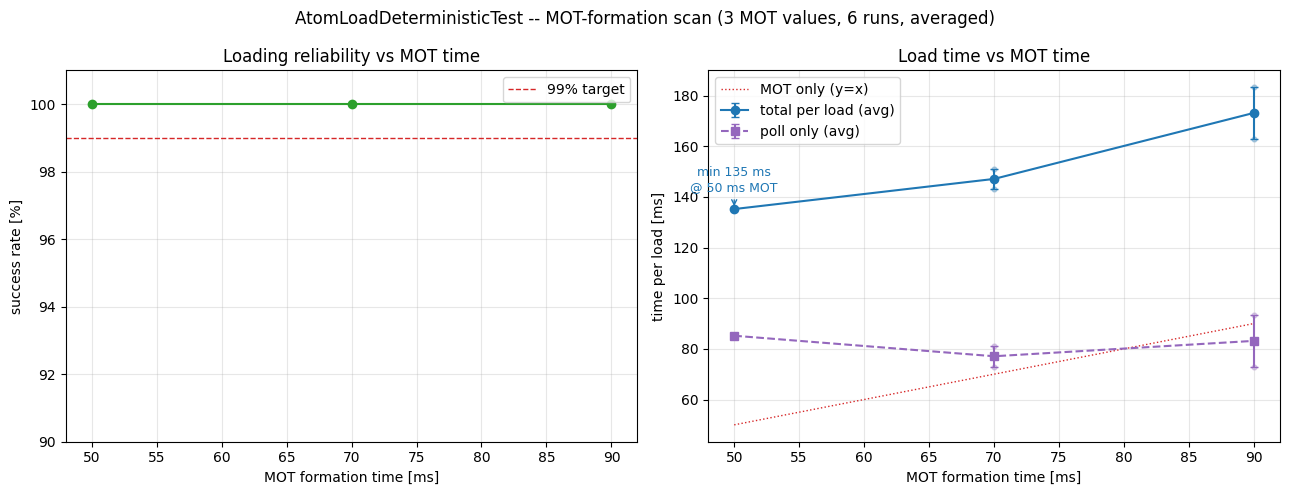

In [32]:
SCAN_RIDS = [3584, 3585, 3586, 3593, 3594, 3595]   # example old runs
paths = [f for f in find_runs() if _rid_of(f) in SCAN_RIDS]
rows = analyze_scan(paths)